# Лабораторна робота №3. Опукла оболонка

**Виконала:** Ткаченко Валентина, група КМ-41

**Варіант:** DS6

**Мета роботи:** Розробити програмний засіб, який знаходить опуклу оболонку множини точок заданих своїми координатами та відображує її на координатній площині і зберігає зображення в одному з графічних форматів.

## Крок 1. Зчитування датасету

In [1]:
def read_dataset(filename):
    points = []
    with open(filename) as f:
        for line in f:
            parts = line.split()
            if len(parts) == 2:
                x = int(parts[0])
                y = int(parts[1])
                points.append((x, y))
    return points

points = read_dataset("DS6.txt")
print("Кількість точок:", len(points))

Кількість точок: 53542


## Крок 2. Пошук опуклої оболонки

In [2]:
def cross(o, a, b):
    return (a[0] - o[0]) * (b[1] - o[1]) - (a[1] - o[1]) * (b[0] - o[0])

def convex_hull(points):
    points = sorted(set(points))

    lower = []
    for p in points:
        while len(lower) >= 2 and cross(lower[-2], lower[-1], p) <= 0:
            lower.pop()
        lower.append(p)

    upper = []
    for p in reversed(points):
        while len(upper) >= 2 and cross(upper[-2], upper[-1], p) <= 0:
            upper.pop()
        upper.append(p)

    return lower[:-1] + upper[:-1]

hull = convex_hull(points)
print("Кількість вершин опуклої оболонки:", len(hull))
print(hull)

Кількість вершин опуклої оболонки: 41
[(88, 242), (92, 230), (105, 193), (142, 88), (144, 83), (145, 81), (146, 80), (148, 79), (153, 78), (163, 78), (663, 80), (673, 81), (694, 88), (699, 91), (703, 94), (709, 100), (864, 304), (868, 310), (870, 314), (872, 319), (875, 333), (875, 349), (867, 445), (866, 448), (863, 451), (858, 453), (854, 454), (849, 455), (839, 456), (238, 456), (228, 455), (222, 454), (218, 453), (209, 450), (197, 444), (185, 435), (181, 431), (176, 425), (172, 419), (167, 409), (88, 244)]


## Крок 3. Збереження опуклої оболонки у файл

In [3]:
def save_dataset(filename, points):
    with open(filename, "w") as f:
        for x, y in points:
            f.write(f"{x} {y}\n")

save_dataset("hull_DS6.txt", hull)
print("Опуклу оболонку збережено у файл hull_DS6.txt")

Опуклу оболонку збережено у файл hull_DS6.txt


## Крок 4. Відображення опуклої оболонки

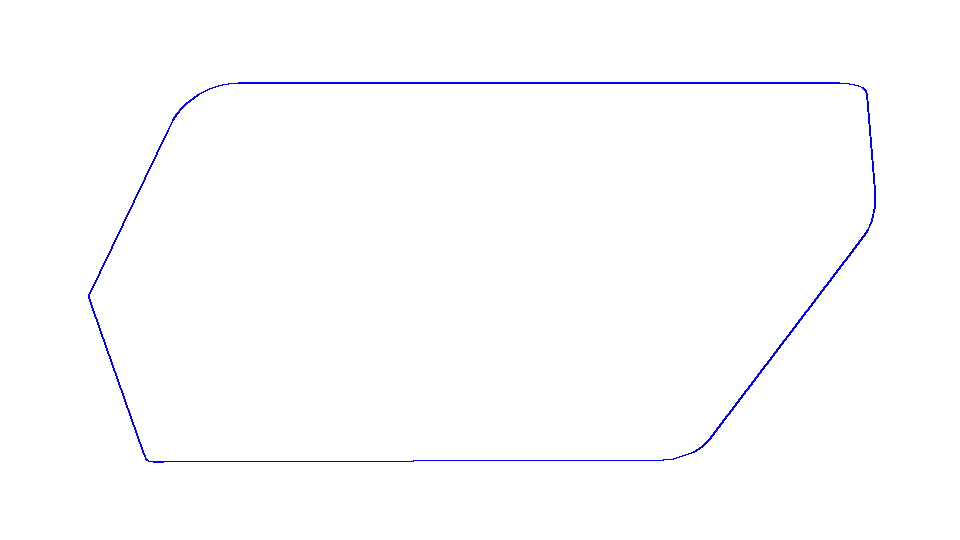

In [4]:
from PIL import Image, ImageDraw

WIDTH = 960
HEIGHT = 540

def to_canvas(x, y):
    return x, HEIGHT - 1 - y

def draw_hull(draw, hull):
    for i in range(len(hull)):
        p1 = to_canvas(*hull[i])
        p2 = to_canvas(*hull[(i + 1) % len(hull)])
        draw.line([p1, p2], fill="blue", width=2)

image_hull = Image.new("RGB", (WIDTH, HEIGHT), "white")
draw = ImageDraw.Draw(image_hull)
draw_hull(draw, hull)

image_hull.save("hull_DS6.png")
image_hull

## Крок 5. Відображення точок разом з опуклою оболонкою

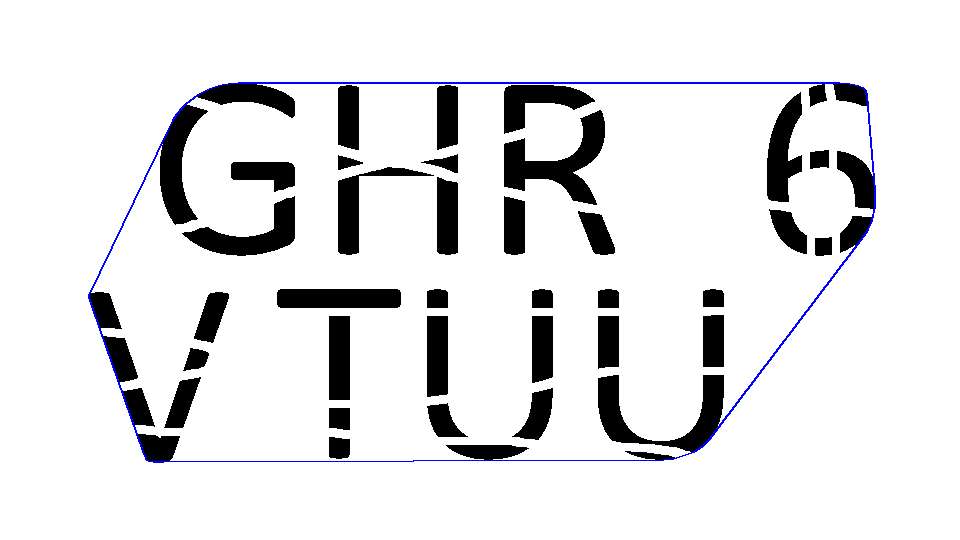

In [5]:
image_result = Image.new("RGB", (WIDTH, HEIGHT), "white")
draw = ImageDraw.Draw(image_result)

for x, y in points:
    draw.point(to_canvas(x, y), fill="black")

draw_hull(draw, hull)

image_result.save("result_DS6.png")
image_result

## Висновок
У цій лабораторній роботі я написала програму на Python, яка знаходить опуклу оболонку множини точок з датасету DS6. Програма зчитує 53 542 точки з файлу, знаходить опуклу оболонку (вийшло 41 вершина), зберігає її в окремий файл hull_DS6.txt і малює її синіми відрізками на полотні 960×540 пікселів окремо (hull_DS6.png) і разом з точками датасету (result_DS6.png).

Перед виконанням я ознайомилася з основними алгоритмами побудови опуклої оболонки:
- **алгоритм Джарвіса** («загортання подарунка») — складність O(n·h), де h — кількість вершин оболонки; простий, але повільний, якщо вершин багато;
- **алгоритм Грехема** — сортує точки за полярним кутом відносно найнижчої точки, складність O(n log n);
- **алгоритм Ендрю (Monotone Chain)** — сортує точки за координатами і окремо будує нижню та верхню частини оболонки, складність O(n log n).

Я обрала алгоритм Ендрю, бо він швидкий і простий у реалізації: не потрібно рахувати кути, достатньо векторного добутку, щоб визначити напрямок повороту. Опуклі оболонки застосовуються в комп'ютерній графіці, розпізнаванні образів, перевірці зіткнень в іграх, геоінформаційних системах і робототехніці.

Для роботи із зображенням я використала бібліотеку **Pillow (PIL)** і такі методи:
- `Image.new()` — щоб створити біле полотно 960×540;
- `ImageDraw.Draw()` — щоб отримати об'єкт для малювання;
- `draw.point()` — щоб намалювати точки датасету;
- `draw.line()` — щоб намалювати відрізки опуклої оболонки синім кольором;
- `image.save()` — щоб зберегти результат у формат PNG.

Для роботи з файлами я використала стандартні засоби Python: `open()`, `split()`, `int()` та `write()`, а для сортування точок — `sorted()`.